# Slicer

In [ ]:
from pathlib import Path


# ==============================================================================
# 3. HELPER: PARSE LABEL STUDIO YOLO .TXT
# ==============================================================================
def load_yolo_boxes_px(label_path: Path, img_w: int, img_h: int):
    """Reads YOLO .txt (either 5-col bbox or multi-col polygon) and returns

    pixel bounding boxes: [(class_id, x1, y1, x2, y2), ...].
    """
    boxes = []
    if not label_path.exists():
        return boxes

    with open(label_path, "r", encoding="utf-8") as f:
        for line in f:
            parts = [float(x) for x in line.strip().split()]
            if len(parts) < 5:
                continue

            cls_id = int(parts[0])
            coords = parts[1:]

            if len(coords) == 4:
                # Standard YOLO bounding box: xc, yc, w, h (normalized)
                xc, yc, bw, bh = coords
                x1 = (xc - bw / 2) * img_w
                y1 = (yc - bh / 2) * img_h
                x2 = (xc + bw / 2) * img_w
                y2 = (yc + bh / 2) * img_h
            else:
                # Label Studio polygon export: x1, y1, x2, y2, ... -> convert to bounding box
                xs = [coords[i] * img_w for i in range(0, len(coords), 2)]
                ys = [coords[i + 1] * img_h for i in range(0, len(coords), 2)]
                x1, y1, x2, y2 = min(xs), min(ys), max(xs), max(ys)

            boxes.append((cls_id, x1, y1, x2, y2))
    return boxes

In [8]:
import cv2
import random

def slice_dataset(
        image_paths: list, 
        ori_dir: Path, 
        out_images_dir: Path, 
        out_labels_dir: Path) -> tuple[int, int]:

    TILE_SIZE = 960  # Target patch size (960x960)
    OVERLAP = 0.35  # 35% overlap so defects near tile edges aren't cut off
    MIN_VISIBILITY = 0.70  # Keep box only if >= 70% of it fits inside the tile
    KEEP_EMPTY_RATIO = 0.15  # Keep 15% of undamaged tiles as "negative" examples
    MAX_BOX_COVERAGE = 0.50 

    stride = int(TILE_SIZE * (1 - OVERLAP))
    positive_tiles = 0
    negative_tiles = 0


    # Loop through all images in the dataset and slice them into tiles
    for img_path in image_paths:
        img = cv2.imread(str(img_path))
        if img is None:
            continue

        img_h, img_w = img.shape[:2]
        label_path = ori_dir / "labels" / f"{img_path.stem}.txt"
        gt_boxes = load_yolo_boxes_px(label_path, img_w, img_h)
        
        max_box_dim = max(
            [max(bx2 - bx1, by2 - by1) for _, bx1, by1, bx2, by2 in gt_boxes],
            default=0,
        )

        # If the defect is a close-up (> 320px), use a larger tile (e.g., 1280x1280) so it gets context
        current_tile_size = TILE_SIZE
        if max_box_dim > TILE_SIZE * MAX_BOX_COVERAGE:
            current_tile_size = min(
                int(max_box_dim / MAX_BOX_COVERAGE), min(img_w, img_h)
            )

        # Generate sliding window top-left coordinates (snapping to right/bottom edges)
        xs = list(range(0, max(1, img_w - current_tile_size + 1), stride))
        if xs[-1] + current_tile_size < img_w:
            xs.append(max(0, img_w - current_tile_size))

        ys = list(range(0, max(1, img_h - current_tile_size + 1), stride))
        if ys[-1] + current_tile_size < img_h:
            ys.append(max(0, img_h - current_tile_size))

        for y0 in ys:
            for x0 in xs:
                x1_tile = min(x0 + current_tile_size, img_w)
                y1_tile = min(y0 + current_tile_size, img_h)
                tile_w = x1_tile - x0
                tile_h = y1_tile - y0

                tile_yolo_lines = []

                for cls_id, bx1, by1, bx2, by2 in gt_boxes:
                    orig_area = max(1.0, (bx2 - bx1) * (by2 - by1))

                    # Clip box to tile boundaries
                    ix1 = max(bx1, x0)
                    iy1 = max(by1, y0)
                    ix2 = min(bx2, x1_tile)
                    iy2 = min(by2, y1_tile)

                    inter_w = max(0.0, ix2 - ix1)
                    inter_h = max(0.0, iy2 - iy1)
                    inter_area = inter_w * inter_h

                    # Keep box only if enough of the defect is visible inside this tile
                    if (inter_area / orig_area) >= MIN_VISIBILITY:
                        # Convert clipped box to normalized tile coordinates (xc, yc, w, h)
                        xc = ((ix1 + ix2) / 2.0 - x0) / tile_w
                        yc = ((iy1 + iy2) / 2.0 - y0) / tile_h
                        bw = inter_w / tile_w
                        bh = inter_h / tile_h
                        tile_yolo_lines.append(f"{cls_id} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")

                # Decide whether to save this tile
                has_defect = len(tile_yolo_lines) > 0
                if has_defect:
                    positive_tiles += 1
                elif random.random() < KEEP_EMPTY_RATIO:
                    negative_tiles += 1
                else:
                    continue  # Skip excess empty background tiles

                tile_name = f"{img_path.stem}_x{x0}_y{y0}"
                tile_img = img[y0:y1_tile, x0:x1_tile]

                cv2.imwrite(str(out_images_dir / f"{tile_name}.jpg"), tile_img)
                with open(out_labels_dir / f"{tile_name}.txt", "w", encoding="utf-8") as f:
                    f.write("\n".join(tile_yolo_lines))
    
    return positive_tiles, negative_tiles

In [ ]:
from pathlib import Path
import yaml

# ==============================================================================
# 1. CONFIGURATION
# ==============================================================================
EXPORT_DIR = Path(
    "../dataset/ls-annotated"
)  # Input from Label Studio YOLO exported dataset
OUTPUT_DIR = Path("../dataset/sliced_dataset")  # Output sliced training dataset

# Get folder names of datasets in the export directory
folders = [f.name for f in EXPORT_DIR.iterdir() if f.is_dir()]

for dsname in folders:
    ori_dir = EXPORT_DIR / dsname
    out_dir = OUTPUT_DIR / dsname
    out_dir.mkdir(parents=True, exist_ok=True)

    print(f"Output directory created: {out_dir.resolve()}")

    # ==============================================================================
    # 2. SETUP OUTPUT FOLDERS & DATA.YAML
    # ==============================================================================

    out_images_dir = out_dir / "images"
    out_labels_dir = out_dir / "labels"
    out_images_dir.mkdir(parents=True, exist_ok=True)
    out_labels_dir.mkdir(parents=True, exist_ok=True)

    with open(ori_dir / "classes.txt", "r", encoding="utf-8") as f:
        class_names = [line.strip() for line in f if line.strip()]

    data_yaml = {
        "path": str(out_dir.resolve()),
        "train": "images",
        "val": "images",  # Split into train/val later or use a separate val folder
        "nc": len(class_names),
        "names": class_names,
    }

    with open(out_dir / "data.yaml", "w", encoding="utf-8") as f:
        yaml.safe_dump(data_yaml, f, sort_keys=False)

    # ==============================================================================
    # 4. SLICE IMAGES & RECALCULATE LABELS
    # ==============================================================================

    image_paths = list((ori_dir / "images").glob("*.jpg")) + list(
        (ori_dir / "images").glob("*.JPG")
    )

    positive_tiles, negative_tiles = slice_dataset(
        image_paths=image_paths,
        ori_dir=ori_dir,
        out_images_dir=out_images_dir,
        out_labels_dir=out_labels_dir,
    )

    print(
        f"Dataset: {dsname} - Processed {len(image_paths)} images, created {positive_tiles} defect tiles and {negative_tiles} background tiles."
    )
    print("=" * 50)

Output directory created: D:\Andy\autolabel\dataset\sliced_dataset\A_aile-fence_light-5-flat
Dataset: A_aile-fence_light-5-flat - Processed 196 images, created 1312 defect tiles and 897 background tiles.
Output directory created: D:\Andy\autolabel\dataset\sliced_dataset\A_aile-fence_warm-flat
Dataset: A_aile-fence_warm-flat - Processed 182 images, created 1966 defect tiles and 423 background tiles.
Output directory created: D:\Andy\autolabel\dataset\sliced_dataset\A_office-gray_light-1-flat
Dataset: A_office-gray_light-1-flat - Processed 220 images, created 1108 defect tiles and 1209 background tiles.
Output directory created: D:\Andy\autolabel\dataset\sliced_dataset\A_office-gray_light-1-gopro
Dataset: A_office-gray_light-1-gopro - Processed 218 images, created 1482 defect tiles and 834 background tiles.
Output directory created: D:\Andy\autolabel\dataset\sliced_dataset\A_office-gray_light-5-flat
Dataset: A_office-gray_light-5-flat - Processed 194 images, created 1678 defect tiles and

## Show sliced images

c:\Users\wapra1274\AppData\Local\miniconda3\envs\wap-autolabel\Lib\site-packages\supervision\annotators\utils.py:192: FutureWarning: `template_mgs` is deprecated since `v0.12` (renamed to `message_template`); use `message_template` instead. Will be removed in `v1.0`.
  @deprecated(  # type: ignore[untyped-decorator]
c:\Users\wapra1274\AppData\Local\miniconda3\envs\wap-autolabel\Lib\site-packages\supervision\annotators\utils.py:280: FutureWarning: `template_mgs` is deprecated since `v0.12` (renamed to `message_template`); use `message_template` instead. Will be removed in `v1.0`.
  @deprecated(  # type: ignore[untyped-decorator]
c:\Users\wapra1274\AppData\Local\miniconda3\envs\wap-autolabel\Lib\site-packages\supervision\annotators\utils.py:325: FutureWarning: `template_mgs` is deprecated since `v0.12` (renamed to `message_template`); use `message_template` instead. Will be removed in `v1.0`.
  @deprecated(  # type: ignore[untyped-decorator]
c:\Users\wapra1274\AppData\Local\miniconda3\en

Show sliced dataset: ..\dataset\sliced_dataset\A_aile-fence_warm-flat
Found 983 positive defect tiles ready for review.


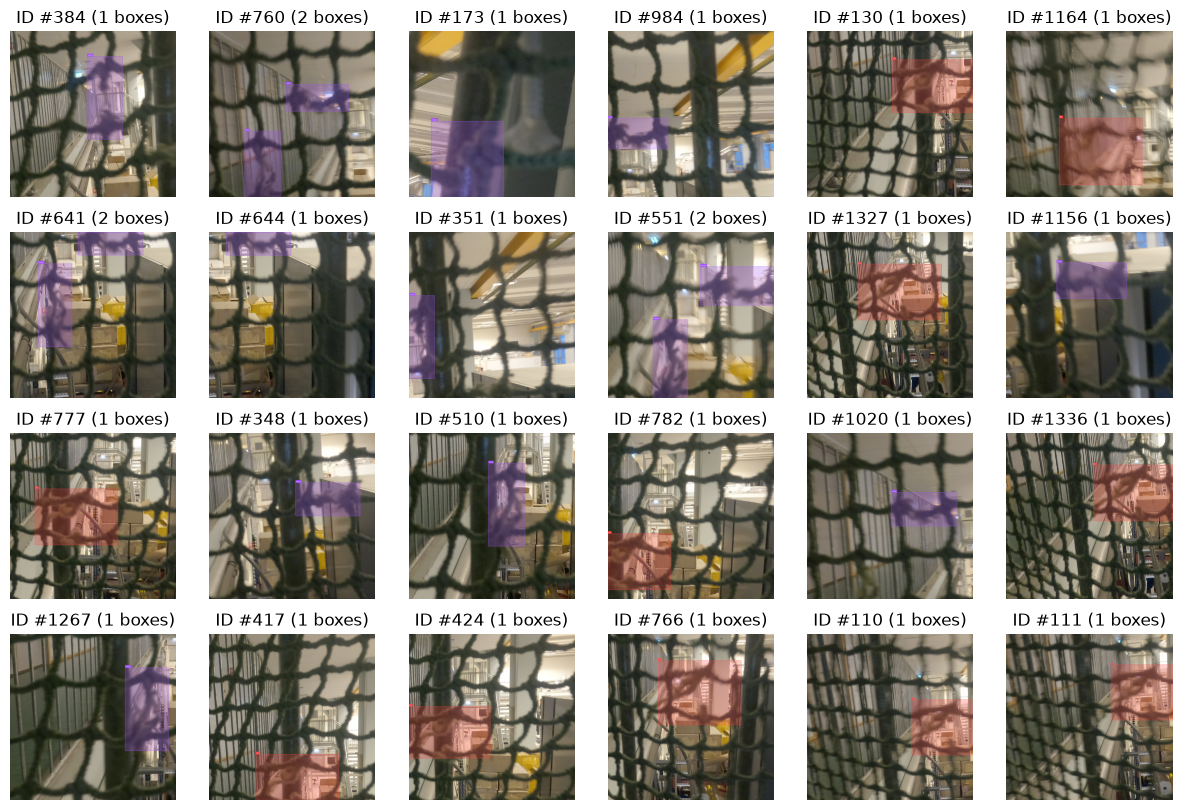

In [1]:
from pathlib import Path
import random
import supervision as sv

# 1. Load the newly sliced YOLO dataset
OUTPUT_DIR = Path("../dataset/sliced_dataset")  # Output sliced training dataset

# Get random folder of datasets
folders = [f for f in OUTPUT_DIR.iterdir() if f.is_dir()]
# selected_ds = random.sample(folders, 1) #A_aile-fence_warm-flat
# ds_path = selected_ds[0]
ds_path = OUTPUT_DIR / "A_aile-fence_warm-flat"

print("Show sliced dataset:", ds_path)

sliced_dataset = sv.DetectionDataset.from_yolo(
    images_directory_path=str(ds_path / "images"),
    annotations_directory_path=str(ds_path / "labels"),
    data_yaml_path=str(ds_path / "data.yaml"),
)

# 2. Filter to keep ONLY positive tiles (tiles that actually contain defect boxes)
positive_items = [
    (idx, img_path, image, annotations)
    for idx, (img_path, image, annotations) in enumerate(sliced_dataset)
    if len(annotations) > 0
]

print(f"Found {len(positive_items)} positive defect tiles ready for review.")

# 3. Sample up to 16 random positive tiles and annotate them
offset = 100
sample_items = random.sample(positive_items, min(24, len(positive_items)))
# sample_items = positive_items[offset:offset+24]  

color_annotator = sv.ColorAnnotator(opacity=0.25)
box_annotator = sv.BoxAnnotator(thickness=2)
label_annotator = sv.LabelAnnotator()

annotated_tiles = []
titles = []

for pos_idx, img_path, image, annotations in sample_items:
    labels = [
        f"{sliced_dataset.classes[class_id]}" for class_id in annotations.class_id
    ]

    annotated = image.copy()
    annotated = color_annotator.annotate(scene=annotated, detections=annotations)
    annotated = box_annotator.annotate(scene=annotated, detections=annotations)
    annotated = label_annotator.annotate(
        scene=annotated, detections=annotations, labels=labels
    )

    annotated_tiles.append(annotated)
    titles.append(f"ID #{pos_idx} ({len(annotations)} boxes)")
#   titles.append(Path(img_path).name)

# 4. Display in a 2x3 grid
sv.plot_images_grid(
    images=annotated_tiles,
    grid_size=(4, 6),
    titles=titles,
    size=(15, 10),
)

# Merge slice batches

In [1]:
from pathlib import Path
import shutil
import yaml

# ==============================================================================
# 1. CONFIGURATION
# ==============================================================================
# List all sliced batch directories you want to combine
OUTPUT_DIR = Path("../dataset/sliced_dataset")
BATCH_DIRS = [
    # OUTPUT_DIR / "A_aile-fence_warm-flat",
    OUTPUT_DIR / "A_aile-fence_light-5-flat",
    OUTPUT_DIR / "A_office-gray_normal-flat",
    # OUTPUT_DIR / "A_office-gray_normal-gopro",
]

MERGED_DIR = Path("../merged_dataset")

# ==============================================================================
# 2. SETUP MERGED DIRECTORY STRUCTURE
# ==============================================================================
merged_images_dir = MERGED_DIR / "images"
merged_labels_dir = MERGED_DIR / "labels"
merged_images_dir.mkdir(parents=True, exist_ok=True)
merged_labels_dir.mkdir(parents=True, exist_ok=True)

# Read class names from the first batch's data.yaml
with open(BATCH_DIRS[0] / "data.yaml", "r", encoding="utf-8") as f:
    first_yaml = yaml.safe_load(f)
class_names = first_yaml["names"]

# ==============================================================================
# 3. MERGE IMAGES & LABELS ACROSS ALL BATCHES
# ==============================================================================
total_images = 0
positive_count = 0
negative_count = 0

for batch_idx, batch_dir in enumerate(BATCH_DIRS, start=1):
    if not batch_dir.exists():
        print(f"Warning: {batch_dir} not found, skipping.")
        continue

    # Verify class names match across batches so class IDs don't get scrambled
    batch_yaml_path = batch_dir / "data.yaml"
    if batch_yaml_path.exists():
        with open(batch_yaml_path, "r", encoding="utf-8") as f:
            batch_classes = yaml.safe_load(f).get("names")
        if batch_classes != class_names:
            raise ValueError(
                f"Class mismatch in {batch_dir}: {batch_classes} != {class_names}"
            )

    batch_images = list((batch_dir / "images").glob("*.jpg")) + list(
        (batch_dir / "images").glob("*.JPG")
    )

    for img_path in batch_images:
        # Prefix with batch name (e.g., 'b1_net01_x0_y0') to prevent filename collisions
        new_stem = f"b{batch_idx}_{img_path.stem}"
        dest_img_path = merged_images_dir / f"{new_stem}{img_path.suffix}"
        dest_lbl_path = merged_labels_dir / f"{new_stem}.txt"

        shutil.copy2(img_path, dest_img_path)

        src_lbl_path = batch_dir / "labels" / f"{img_path.stem}.txt"
        if src_lbl_path.exists():
            shutil.copy2(src_lbl_path, dest_lbl_path)
            # Check whether this tile is positive (has boxes) or negative (empty)
            if src_lbl_path.stat().st_size > 0:
                positive_count += 1
            else:
                negative_count += 1
        else:
            # Create an empty .txt file if missing so background tiles are preserved cleanly
            dest_lbl_path.touch()
            negative_count += 1

        total_images += 1

# ==============================================================================
# 4. WRITE UNIFIED DATA.YAML
# ==============================================================================
merged_yaml = {
    "path": str(MERGED_DIR.resolve()),
    "train": "images",
    "val": "images",
    "nc": len(class_names),
    "names": class_names,
}
with open(MERGED_DIR / "data.yaml", "w", encoding="utf-8") as f:
    yaml.safe_dump(merged_yaml, f, sort_keys=False)

print(f"Merged {len(BATCH_DIRS)} batches into: {MERGED_DIR.resolve()}")
print(
    f"Total tiles: {total_images} ({positive_count} positive defect tiles,"
    f" {negative_count} negative background tiles)"
)

Merged 2 batches into: D:\Andy\autolabel\merged_dataset
Total tiles: 6066 (2964 positive defect tiles, 3102 negative background tiles)


# Dataset split for training

In [2]:
from collections import defaultdict
from pathlib import Path
import random
import re
import shutil
import yaml


def split_yolo_dataset(
    merged_dir: Path,
    split_dir: Path,
    val_ratio: float = 0.20,
    seed: int = 42,
):
  """Splits a merged sliced YOLO dataset into train/ and val/ folders,

  grouping all tiles from the same original photo to prevent data leakage.
  """
  random.seed(seed)

  images_dir = merged_dir / "images"
  labels_dir = merged_dir / "labels"

  with open(merged_dir / "data.yaml", "r", encoding="utf-8") as f:
    merged_yaml = yaml.safe_load(f)
  class_names = merged_yaml["names"]

  # 1. Group tiles by original source photo (strips trailing '_x123_y456')
  groups = defaultdict(list)
  image_paths = list(images_dir.glob("*.jpg")) + list(images_dir.glob("*.JPG"))

  for img_path in image_paths:
    source_id = re.sub(r"_x\d+_y\d+$", "", img_path.stem)
    groups[source_id].append(img_path)

  # 2. Shuffle source photos and split 80/20 at the photo level
  source_ids = list(groups.keys())
  random.shuffle(source_ids)

  val_count = max(1, int(len(source_ids) * val_ratio))
  val_sources = set(source_ids[:val_count])
  train_sources = set(source_ids[val_count:])

  # 3. Copy images and labels into train/ and val/ directory structure
  stats = {
      "train": {"pos": 0, "neg": 0},
      "val": {"pos": 0, "neg": 0},
  }

  for split_name, sources in [("train", train_sources), ("val", val_sources)]:
    out_img_dir = split_dir / split_name / "images"
    out_lbl_dir = split_dir / split_name / "labels"
    out_img_dir.mkdir(parents=True, exist_ok=True)
    out_lbl_dir.mkdir(parents=True, exist_ok=True)

    for src_id in sources:
      for img_path in groups[src_id]:
        shutil.copy2(img_path, out_img_dir / img_path.name)

        src_lbl = labels_dir / f"{img_path.stem}.txt"
        dst_lbl = out_lbl_dir / f"{img_path.stem}.txt"

        if src_lbl.exists():
          shutil.copy2(src_lbl, dst_lbl)
          if src_lbl.stat().st_size > 0:
            stats[split_name]["pos"] += 1
          else:
            stats[split_name]["neg"] += 1
        else:
          dst_lbl.touch()
          stats[split_name]["neg"] += 1

  # 4. Write final YOLO data.yaml pointing to train/images and val/images
  final_yaml = {
      "path": str(split_dir.resolve()),
      "train": "train/images",
      "val": "val/images",
      "nc": len(class_names),
      "names": class_names,
  }
  with open(split_dir / "data.yaml", "w", encoding="utf-8") as f:
    yaml.safe_dump(final_yaml, f, sort_keys=False)

  print(
      f"Split {len(source_ids)} source photos -> {len(train_sources)} train,"
      f" {len(val_sources)} val"
  )
  print(
      f"Train tiles: {stats['train']['pos']} defect,"
      f" {stats['train']['neg']} background"
  )
  print(
      f"Val tiles:   {stats['val']['pos']} defect,"
      f" {stats['val']['neg']} background"
  )
  print(f"Ready for YOLO training at: {(split_dir / 'data.yaml').resolve()}")


split_yolo_dataset(
    merged_dir=Path("../merged_dataset"),
    split_dir=Path("../dataset/yolo_train_net-a"),
    val_ratio=0.20,
    seed=42,
)


Split 206 source photos -> 165 train, 41 val
Train tiles: 2368 defect, 2436 background
Val tiles:   596 defect, 666 background
Ready for YOLO training at: D:\Andy\autolabel\dataset\yolo_train_net-a\data.yaml
